# Librerias

In [2]:
!pip install -r ../requirements.txt

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, date, timedelta
import seaborn as sns
from typing import Optional

import os
import pickle

from sklearn import preprocessing

# Carga Data

In [4]:
df_data = pd.read_csv(
    "../data/01_raw/Base.csv",
    dtype={

    },
)

In [5]:
df_data.head()

,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


In [6]:
df_data.shape

(1000000, 32)

In [7]:
df_data.dtypes

fraud_bool                            int64
income                              float64
name_email_similarity               float64
prev_address_months_count             int64
current_address_months_count          int64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                            str
zip_count_4w                          int64
velocity_6h                         float64
velocity_24h                        float64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                       str
credit_risk_score                     int64
email_is_free                         int64
housing_status                          str
phone_home_valid                      int64
phone_mobile_valid                    int64
bank_months_count                     int64
has_other_cards                 

In [8]:
df_data.isna().sum()

fraud_bool                          0
income                              0
name_email_similarity               0
prev_address_months_count           0
current_address_months_count        0
customer_age                        0
days_since_request                  0
intended_balcon_amount              0
payment_type                        0
zip_count_4w                        0
velocity_6h                         0
velocity_24h                        0
velocity_4w                         0
bank_branch_count_8w                0
date_of_birth_distinct_emails_4w    0
employment_status                   0
credit_risk_score                   0
email_is_free                       0
housing_status                      0
phone_home_valid                    0
phone_mobile_valid                  0
bank_months_count                   0
has_other_cards                     0
proposed_credit_limit               0
foreign_request                     0
source                              0
session_leng

# Renombrar variables

In [9]:
df_data["month"].unique()

array([0, 1, 2, 3, 4, 5, 6, 7])

In [10]:
# Quiero renombrar la variable "fraud_bool" como "target" en df_data
df_data.rename(columns={'fraud_bool': 'target'}, inplace=True)

# SUPUESTO: Month hace referencia a 2024-01 a 2024-07
df_data.rename(columns={'month': 'period'}, inplace=True)

# Exactitud

In [11]:
month_map = {
    0: "2024-01",
    1: "2024-02",
    2: "2024-03",
    3: "2024-04",
    4: "2024-05",
    5: "2024-06",
    6: "2024-07",
    7: "2024-08",
}

# Cambiar tipos de datos

In [12]:
df_data["period"] = pd.to_datetime(df_data["period"].map(month_map))

In [13]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,period
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,2024-01-01
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,2024-01-01
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,2024-01-01
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,2024-01-01
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,2024-01-01


In [14]:
df_data["period"].unique()

<DatetimeArray>
['2024-01-01 00:00:00', '2024-02-01 00:00:00', '2024-03-01 00:00:00',
 '2024-04-01 00:00:00', '2024-05-01 00:00:00', '2024-06-01 00:00:00',
 '2024-07-01 00:00:00', '2024-08-01 00:00:00']
Length: 8, dtype: datetime64[us]

# Estadísticos y Percentiles

In [15]:
# ------------------------------------------
# 1) Selección de variables numéricas
# ------------------------------------------

num_cols = df_data.select_dtypes(include=[np.number]).columns.tolist()

# (Opcional) Excluir columnas numéricas que en realidad son IDs (si aplica)
# excl = ['ID_CLIENTE', 'CODIGO', ...]
# num_cols = [c for c in num_cols if c not in excl]


# ------------------------------------------
# 2) TABLA 1: Resumen estadístico
#    (Mean, Std, Min, Max, N, N Miss)
# ------------------------------------------

t1 = pd.DataFrame({
    'Variable': num_cols,
    'Label': num_cols  # En tu ejemplo el Label es igual al nombre
})

# Estadísticos principales
t1['Mean'] = [
    df_data[c].mean(skipna=True)
    for c in num_cols
]

t1['Std Dev'] = [
    df_data[c].std(skipna=True, ddof=1)
    for c in num_cols
]

t1['Minimum'] = [
    df_data[c].min(skipna=True)
    for c in num_cols
]

t1['Maximum'] = [
    df_data[c].max(skipna=True)
    for c in num_cols
]

# Conteos
t1['N'] = [
    df_data[c].notna().sum()
    for c in num_cols
]  # no nulos

t1['N Miss'] = [
    df_data[c].isna().sum()
    for c in num_cols
]  # nulos

# (Opcional) Ordenar por nombre
t1 = t1.sort_values('Variable').reset_index(drop=True)

t1

,Variable,Label,Mean,Std Dev,Minimum,Maximum,N,N Miss
0,bank_branch_count_8w,bank_branch_count_8w,184.361849,459.625329,0.000000e+00,2385.000000,1000000,0
1,bank_months_count,bank_months_count,10.839303,12.116875,-1.000000e+00,32.000000,1000000,0
2,credit_risk_score,credit_risk_score,130.989595,69.681812,-1.700000e+02,389.000000,1000000,0
3,current_address_months_count,current_address_months_count,86.587867,88.406599,-1.000000e+00,428.000000,1000000,0
4,customer_age,customer_age,33.689080,12.025799,1.000000e+01,90.000000,1000000,0
5,date_of_birth_distinct_emails_4w,date_of_birth_distinct_emails_4w,9.503544,5.033792,0.000000e+00,39.000000,1000000,0
6,days_since_request,days_since_request,1.025705,5.381835,4.036860e-09,78.456904,1000000,0
7,device_distinct_emails_8w,device_distinct_emails_8w,1.018312,0.180761,-1.000000e+00,2.000000,1000000,0
8,device_fraud_count,device_fraud_count,0.000000,0.000000,0.000000e+00,0.000000,1000000,0
9,email_is_free,email_is_free,0.529886,0.499106,0.000000e+00,1.000000,1000000,0


In [16]:
# ------------------------------------------
# 3) TABLA 2: Percentiles
#    (5, 10, 25, 50, 75, 90, 95, 99)
# ------------------------------------------

percentiles = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]

q = df_data[num_cols].quantile(
    percentiles,
    interpolation='linear'
).T

# Renombrar columnas a tu formato
q = (
    q.rename(columns={
        0.05: '5th Pctl',
        0.10: '10th Pctl',
        0.25: 'Lower Quartile',
        0.50: 'Median',
        0.75: 'Upper Quartile',
        0.90: '90th Pctl',
        0.95: '95th Pctl',
        0.99: '99th Pctl'
    })
    .reset_index()
    .rename(columns={'index': 'Variable'})
)

# (Opcional) Ordenar por Variable
t2 = q.sort_values('Variable').reset_index(drop=True)

In [17]:
# ------------------------------------------
# 4) (Opcional) Formato visual tipo reporte
#    (sin cambiar valores base)
# ------------------------------------------

# Si lo quieres como en la imagen (2 decimales), crea versiones formateadas

t1_fmt = t1.copy()

for col in ['Mean', 'Std Dev', 'Minimum', 'Maximum']:
    t1_fmt[col] = t1_fmt[col].map(
        lambda x: np.nan if pd.isna(x) else round(x, 2)
    )

t2_fmt = t2.copy()

for col in [
    '5th Pctl',
    '10th Pctl',
    'Lower Quartile',
    'Median',
    'Upper Quartile',
    '90th Pctl',
    '95th Pctl',
    '99th Pctl'
]:
    t2_fmt[col] = t2_fmt[col].map(
        lambda x: np.nan if pd.isna(x) else round(x, 2)
    )

# ------------------------------------------
# 5) Mostrar / Exportar
# ------------------------------------------

# Mostrar en notebook
display(t1_fmt)
display(t2_fmt)

# Exportar a Excel (dos hojas)
#archivo = r'modelo_cancelacion_anticipada_dpf/data/08_reporting/descriptivos_universo_seleccionado_v6.xlsx'
archivo = r'../data/08_reporting/descriptivos_universo_seleccionado.xlsx'

with pd.ExcelWriter(archivo, engine='openpyxl') as writer:
    t1_fmt.to_excel(writer, sheet_name='Resumen', index=False)
    t2_fmt.to_excel(writer, sheet_name='Percentiles', index=False)

,Variable,Label,Mean,Std Dev,Minimum,Maximum,N,N Miss
0,bank_branch_count_8w,bank_branch_count_8w,184.36,459.63,0.00,2385.00,1000000,0
1,bank_months_count,bank_months_count,10.84,12.12,-1.00,32.00,1000000,0
2,credit_risk_score,credit_risk_score,130.99,69.68,-170.00,389.00,1000000,0
3,current_address_months_count,current_address_months_count,86.59,88.41,-1.00,428.00,1000000,0
4,customer_age,customer_age,33.69,12.03,10.00,90.00,1000000,0
5,date_of_birth_distinct_emails_4w,date_of_birth_distinct_emails_4w,9.50,5.03,0.00,39.00,1000000,0
6,days_since_request,days_since_request,1.03,5.38,0.00,78.46,1000000,0
7,device_distinct_emails_8w,device_distinct_emails_8w,1.02,0.18,-1.00,2.00,1000000,0
8,device_fraud_count,device_fraud_count,0.00,0.00,0.00,0.00,1000000,0
9,email_is_free,email_is_free,0.53,0.50,0.00,1.00,1000000,0


,Variable,5th Pctl,10th Pctl,Lower Quartile,Median,Upper Quartile,90th Pctl,95th Pctl,99th Pctl
0,bank_branch_count_8w,0.00,0.00,1.00,9.00,25.00,750.00,1463.00,1974.00
1,bank_months_count,-1.00,-1.00,-1.00,5.00,25.00,29.00,30.00,31.00
2,credit_risk_score,28.00,48.00,83.00,122.00,178.00,226.00,255.00,305.00
3,current_address_months_count,3.00,7.00,19.00,52.00,130.00,214.00,277.00,370.00
4,customer_age,20.00,20.00,20.00,30.00,40.00,50.00,50.00,60.00
5,date_of_birth_distinct_emails_4w,2.00,4.00,6.00,9.00,13.00,16.00,19.00,23.00
6,days_since_request,0.00,0.00,0.01,0.02,0.03,0.05,6.68,22.00
7,device_distinct_emails_8w,1.00,1.00,1.00,1.00,1.00,1.00,1.00,2.00
8,device_fraud_count,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
9,email_is_free,0.00,0.00,0.00,1.00,1.00,1.00,1.00,1.00


# Analisis Outliers

In [18]:
# ------------------------------------------
# 1) Variables numéricas
# ------------------------------------------

num_cols = df_data.select_dtypes(
    include=[np.number]
).columns

total_rows = len(df_data)

outlier_summary = []


# ------------------------------------------
# 2) Cálculo de outliers por variable
# ------------------------------------------

for col in num_cols:

    s = df_data[col].dropna()

    # Evitar columnas constantes
    std = s.std(ddof=1)

    if std == 0 or pd.isna(std):
        outliers_count = 0
    else:
        mean = s.mean()
        z = (s - mean) / std
        outliers_count = (z.abs() > 3).sum()

    outlier_summary.append({
        'Variable': col,
        'Cantidad outliers': outliers_count,
        'Porcentaje del total de datos': f'{outliers_count / total_rows:.2%}'
    })


# ------------------------------------------
# 3) Tabla final
# ------------------------------------------

tabla_outliers = pd.DataFrame(outlier_summary)

# (Opcional) Ordenar de mayor a menor impacto
tabla_outliers = tabla_outliers.sort_values(
    'Cantidad outliers',
    ascending=False
).reset_index(drop=True)

tabla_outliers

,Variable,Cantidad outliers,Porcentaje del total de datos
0,bank_branch_count_8w,40984,4.10%
1,device_distinct_emails_8w,31933,3.19%
2,prev_address_months_count,25310,2.53%
3,foreign_request,25242,2.52%
4,session_length_in_minutes,23593,2.36%
5,current_address_months_count,21483,2.15%
6,intended_balcon_amount,18960,1.90%
7,days_since_request,17775,1.78%
8,zip_count_4w,16247,1.62%
9,target,11029,1.10%


# Desbalance de clase

In [19]:
# Contar los valores de target
target_counts = df_data['target'].value_counts()

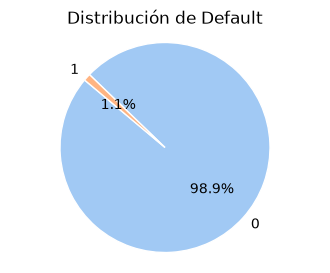


Conteo total de clases en el target:
target
0    988971
1     11029
Name: count, dtype: int64


In [20]:
import seaborn as sns

# --- 1. Contar los valores del target en TODO el dataset ---
# Usamos .value_counts() directamente sobre la columna 'target' del DataFrame completo
total_target_counts = df_data['target'].value_counts()

# --- 2. Definir los colores para mantener la consistencia ---
# Por defecto, Matplotlib usa azul para la primera categoría (0) y naranja para la segunda (1).
# Podemos definirlos explícitamente para asegurarnos.
colors = sns.color_palette('pastel')[0:2] # Usamos una paleta 'pastel' de seaborn

# --- 3. Crear el gráfico circular ---
plt.figure(figsize=(4, 3)) # Un poco más grande para que sea el gráfico principal

# Usamos los conteos totales para el pie chart
# autopct='%1.1f%%' muestra los porcentajes con un decimal
# startangle=140 rota el gráfico para una mejor visualización inicial
# textprops para hacer la fuente un poco más grande
plt.pie(
    total_target_counts,
    labels=total_target_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops={'edgecolor': 'white'}, # Borde blanco entre porciones
    textprops={'fontsize': 10}
)

# --- 4. Añadir título y asegurar el formato circular ---
plt.title('Distribución de Default', fontsize=12)
plt.axis('equal')  # Asegura que el gráfico sea un círculo perfecto

# Mostrar el gráfico
plt.show()

# Opcional: Imprimir los conteos exactos para tener el número además del porcentaje
print("\nConteo total de clases en el target:")
print(total_target_counts)

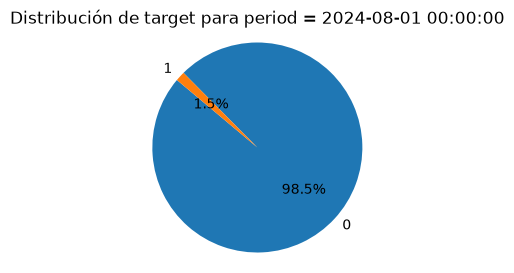

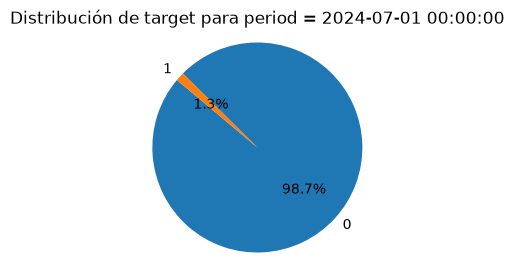

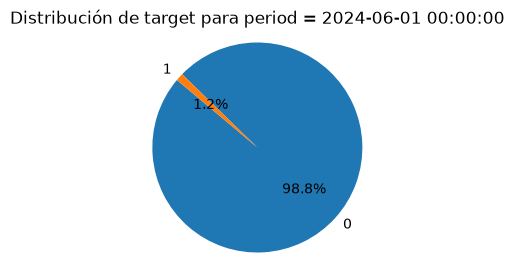

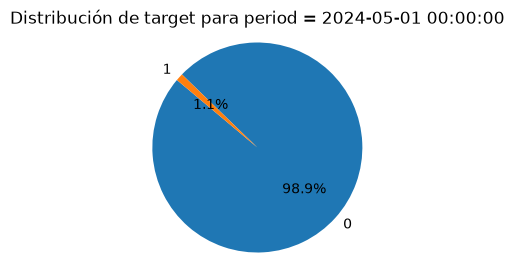

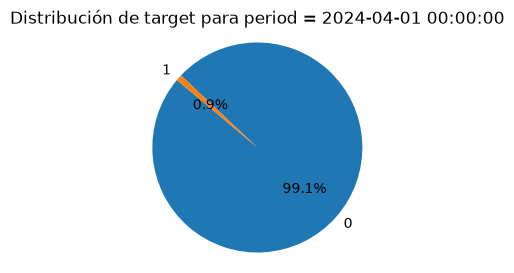

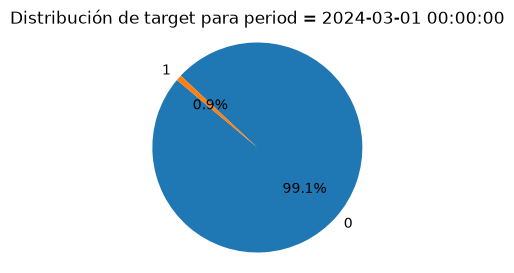

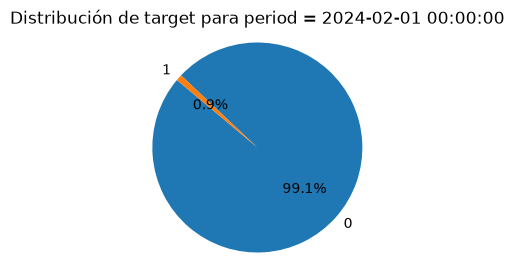

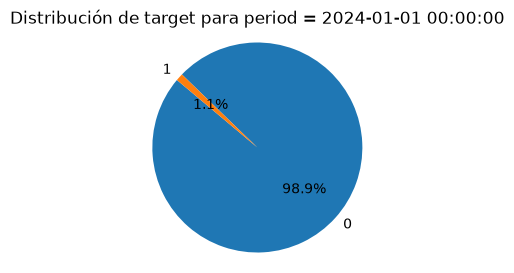

In [21]:
### Obtener los valores únicos de period y ordenarlos de forma descendente
periodos_unicos = sorted(df_data['period'].unique(), reverse=True)

# Crear un gráfico circular para cada period (en orden descendente)
for periodo in periodos_unicos:
    # Filtrar el DataFrame para el periodo actual
    df_periodo = df_data[df_data['period'] == periodo]

    # Contar los valores de target
    target_counts = df_periodo['target'].value_counts()

    # Crear el gráfico circular
    plt.figure(figsize=(4, 3))
    plt.pie(target_counts, labels=target_counts.index, autopct='%1.1f%%', startangle=140)
    plt.title(f'Distribución de target para period = {periodo}')
    plt.axis('equal')  # Asegurar que el gráfico sea un círculo

    # Mostrar el gráfico
    plt.show()

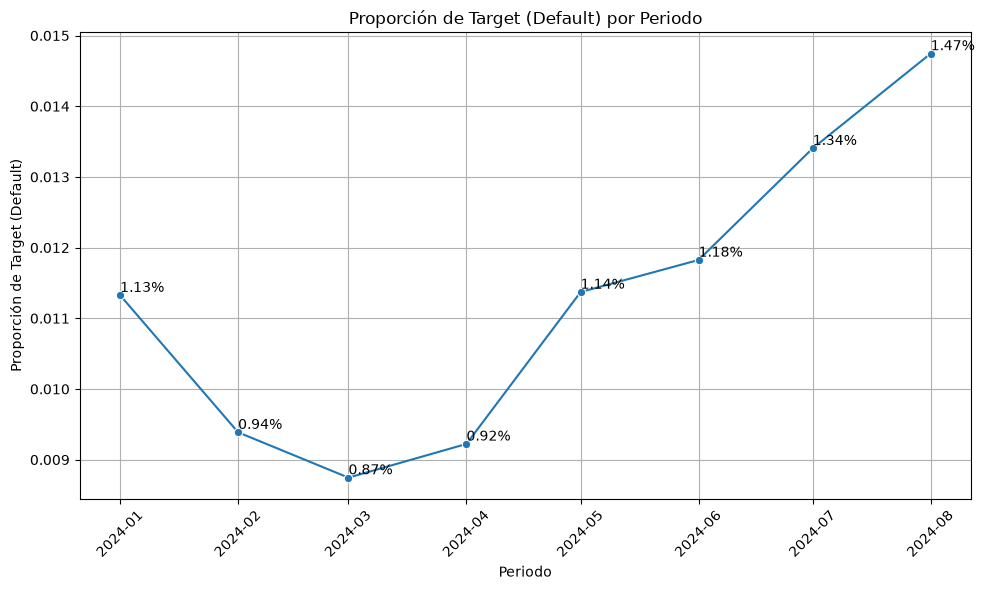

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Eliminar filas con NaT en la columna 'period' para evitar errores de graficado
df_data_cleaned = df_data.dropna(subset=['period']).copy()

# Agrupar por 'period' y calcular la media de 'target'
# La media de un target binario (0, 1) representa la proporción de 1s.
target_by_period = df_data_cleaned.groupby('period')['target'].mean().reset_index()

# Crear el gráfico de líneas
plt.figure(figsize=(10, 6))
sns.lineplot(x='period', y='target', data=target_by_period, marker='o')

# Añadir etiquetas a cada punto
for index, row in target_by_period.iterrows():
    plt.text(row['period'], row['target'], f"{row['target']:.2%}", color='black', ha="left", va="bottom")

# Añadir título y etiquetas
plt.title('Proporción de Target (Default) por Periodo')
plt.xlabel('Periodo')
plt.ylabel('Proporción de Target (Default)')

# Formatear el eje X para mostrar fechas claramente
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Imputación de Datos

No hay datos nulos